## ML Process Implementation

Import all the needed libraries and packages



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Data Collection

We will use the Seoul Bike dataset available in Python. 

In [5]:
# Import the Seoul Bike dataset from a CSV file
data = pd.read_csv("SeoulBikeData.csv", encoding="cp949")

# Confirm that the dataset has been loaded
print("Seoul Bike dataset successfully loaded!")

# Display the first 10 records
print("\nFIRST 10 RECORDS:")
print(data.head(10))

Seoul Bike dataset successfully loaded!

FIRST 10 RECORDS:
         Date  Rented Bike Count  Hour  ...  Seasons     Holiday  Functioning Day
0  01/12/2017                254     0  ...   Winter  No Holiday              Yes
1  01/12/2017                204     1  ...   Winter  No Holiday              Yes
2  01/12/2017                173     2  ...   Winter  No Holiday              Yes
3  01/12/2017                107     3  ...   Winter  No Holiday              Yes
4  01/12/2017                 78     4  ...   Winter  No Holiday              Yes
5  01/12/2017                100     5  ...   Winter  No Holiday              Yes
6  01/12/2017                181     6  ...   Winter  No Holiday              Yes
7  01/12/2017                460     7  ...   Winter  No Holiday              Yes
8  01/12/2017                930     8  ...   Winter  No Holiday              Yes
9  01/12/2017                490     9  ...   Winter  No Holiday              Yes

[10 rows x 14 columns]


## Exploratory Data Analysis (EDA)

We may perform data analysis to better understand the dataset

In [6]:
print("\nDATASET SIZE:")
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

print("\nCOLUMN NAMES:")
print(data.columns)

print("\nDATASET INFORMATION:")
data.info()

print("\nMISSING VALUES:")
print(data.isnull().sum())

print("\nDESCRIPTIVE STATISTICS:")
print(data.describe())


print("\n SHAPE BEFORE CLEANING:")
print(data.shape)

empty_columns = [c for c in data.columns if data[c].isnull().all()]
print("\n EMPTY COLUMNS: ")
print(empty_columns)

data = data.drop(columns=empty_columns)
print("\nDROPPED EMPTY COLUMNS")

print("\nMISSING VALUES AFTER CLEANING:")
print(data.isnull().sum())

print("\nDUPLICATE ROWS:")
print(data.duplicated().sum())

print("\n SHAPE AFTER CLEANING:")
print(data.shape)


DATASET SIZE:
Rows: 8760
Columns: 14

COLUMN NAMES:
Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(캜)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(캜)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='str')

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      8760 non-null   str    
 1   Rented Bike Count         8760 non-null   int64  
 2   Hour                      8760 non-null   int64  
 3   Temperature(캜)            8760 non-null   float64
 4   Humidity(%)               8760 non-null   int64  
 5   Wind speed (m/s)          8760 non-null   float64
 6   Visibility (10m)          8760 non-null   int64  
 7   Dew point temperature(캜)  8760 non-null   

## Some Data Visualization

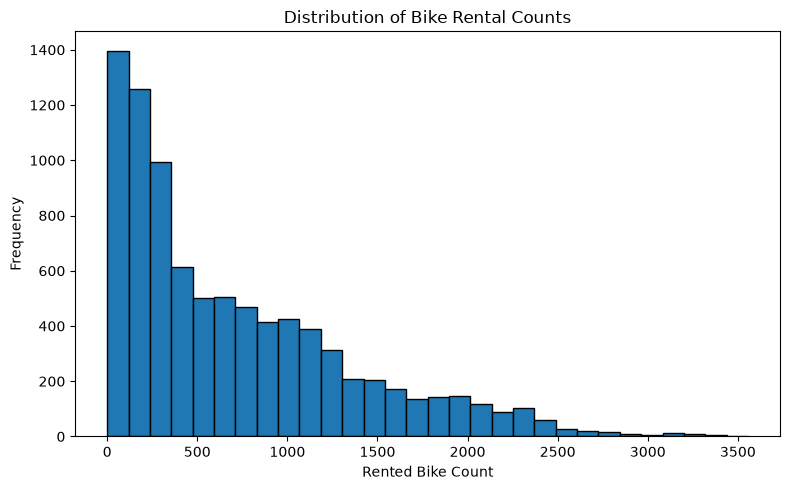

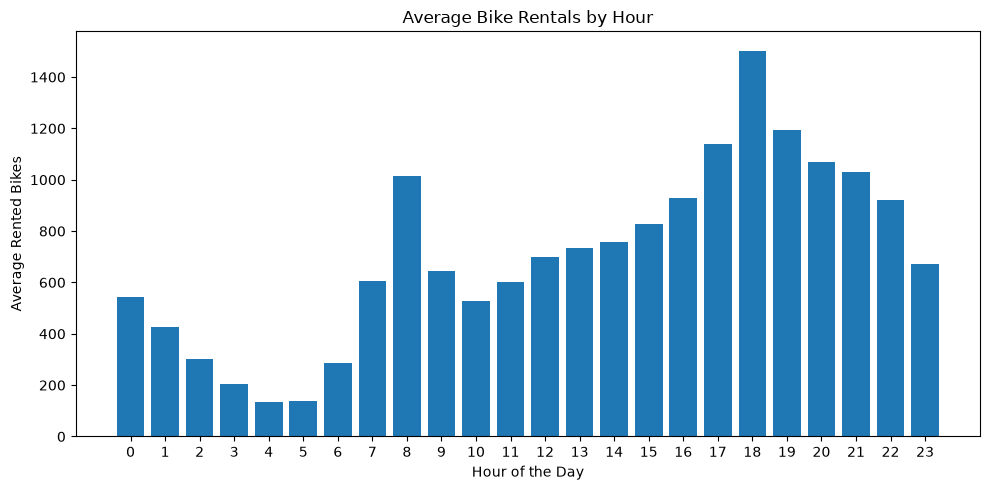

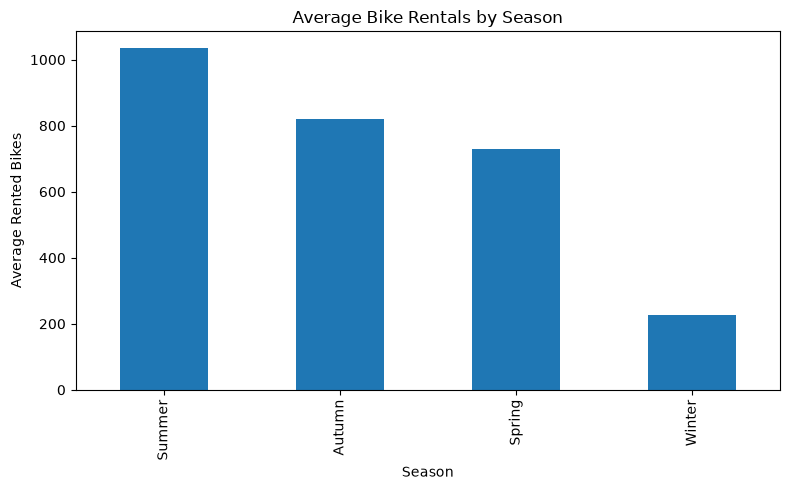

C:\Users\Adrian\AppData\Local\Temp\ipykernel_21012\3194441221.py:51: UserWarning: Glyph 52892 (\N{HANGUL SYLLABLE KAELS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Adrian\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52892 (\N{HANGUL SYLLABLE KAELS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


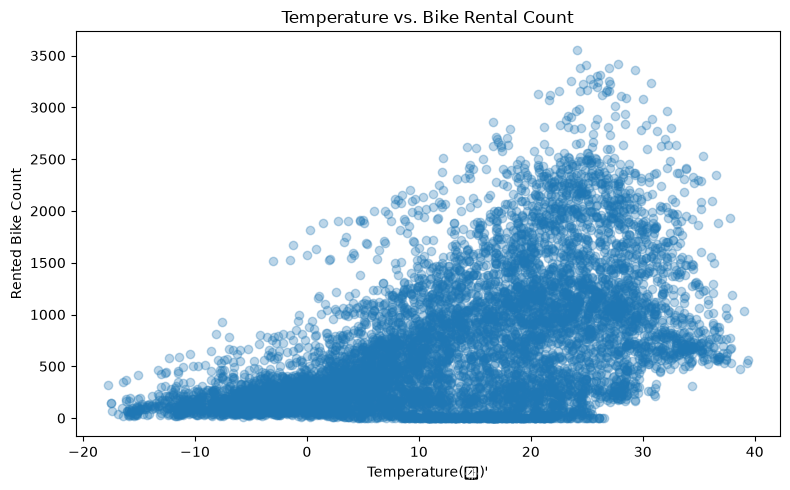

In [7]:
# A. Distribution of bike rental counts

plt.figure(figsize=(8, 5))
plt.hist(data["Rented Bike Count"], bins=30, edgecolor="black")
plt.title("Distribution of Bike Rental Counts")
plt.xlabel("Rented Bike Count")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# B. Average rentals by hour

hourly_rentals = data.groupby("Hour")["Rented Bike Count"].mean()

plt.figure(figsize=(10, 5))
plt.bar(hourly_rentals.index, hourly_rentals.values)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rented Bikes")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


# C. Average rentals by season
seasonal_rentals = data.groupby("Seasons")["Rented Bike Count"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
seasonal_rentals.plot(kind="bar")
plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Rented Bikes")
plt.tight_layout()
plt.show()

# D. Temperature vs. Bike Rental Count

plt.figure(figsize=(8, 5))

plt.scatter(
    data["Temperature(캜)"],
    data["Rented Bike Count"],
    alpha=0.3
)

plt.title("Temperature vs. Bike Rental Count")
plt.xlabel("Temperature(캜)'")
plt.ylabel("Rented Bike Count")

plt.tight_layout()
plt.show()



## Preprocessing

In [8]:
# Create a copy of the dataset
processed_data = data.copy()

# Remove leading and trailing spaces from column names
# processed_data.columns = processed_data.columns.str.strip()

# Handle missing values
# processed_data = processed_data.dropna()

# Create a binary target based on the median rental count
median_rentals = processed_data["Rented Bike Count"].median()

processed_data["Demand Level"] = (
    processed_data["Rented Bike Count"] >= median_rentals
).astype(int)

print("PREPROCESSING RESULTS:")
print("Dataset shape:", processed_data.shape)
print("Median rental count:", median_rentals)
print("\nDemand Level distribution:")
print(processed_data["Demand Level"].value_counts())
print("\nMissing values:")
print(processed_data.isnull().sum())

PREPROCESSING RESULTS:
Dataset shape: (8760, 15)
Median rental count: 504.5

Demand Level distribution:
Demand Level
0    4380
1    4380
Name: count, dtype: int64

Missing values:
Date                        0
Rented Bike Count           0
Hour                        0
Temperature(캜)              0
Humidity(%)                 0
Wind speed (m/s)            0
Visibility (10m)            0
Dew point temperature(캜)    0
Solar Radiation (MJ/m2)     0
Rainfall(mm)                0
Snowfall (cm)               0
Seasons                     0
Holiday                     0
Functioning Day             0
Demand Level                0
dtype: int64


## Feature Engineering

FEATURE ENGINEERING RESULTS:
Number of features: 36

Feature names:
['Hour', 'Temperature(캜)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(캜)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons_Autumn', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Holiday_Holiday', 'Holiday_No Holiday', 'Functioning Day_No', 'Functioning Day_Yes', 'Month_1', 'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Day of Week_0', 'Day of Week_1', 'Day of Week_2', 'Day of Week_3', 'Day of Week_4', 'Day of Week_5', 'Day of Week_6']

Target variable:
Demand Level
0    4380
1    4380
Name: count, dtype: int64


C:\Users\Adrian\AppData\Local\Temp\ipykernel_21012\4261978099.py:68: UserWarning: Glyph 52892 (\N{HANGUL SYLLABLE KAELS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Adrian\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52892 (\N{HANGUL SYLLABLE KAELS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


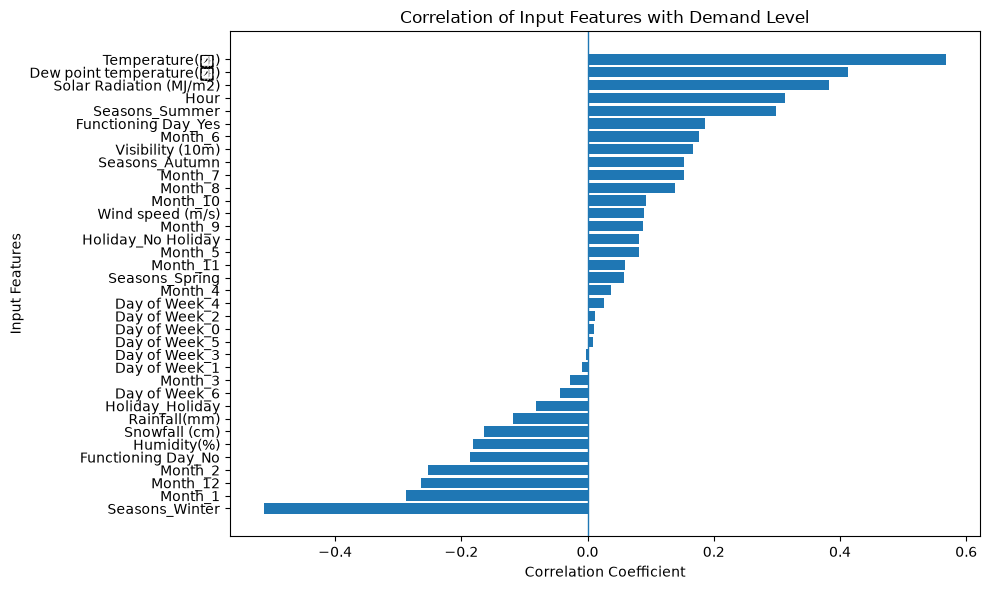

In [9]:
# Convert Date into a datetime format
processed_data["Date"] = pd.to_datetime(
    processed_data["Date"], dayfirst=True, errors="coerce"
)

# Create additional date-based features
processed_data["Month"] = processed_data["Date"].dt.month
processed_data["Day of Week"] = processed_data["Date"].dt.dayofweek

processed_data["Month"] = (
    processed_data["Month"].astype(str)
)

processed_data["Day of Week"] = (
    processed_data["Day of Week"].astype(str)
)

# Select input features and exclude the target and original rental count
X = processed_data.drop(
    columns=["Rented Bike Count", "Demand Level", "Date"]
)

# Encode categorical variables
X = pd.get_dummies(X, dtype=int)

# Define the target variable
y = processed_data["Demand Level"]

print("FEATURE ENGINEERING RESULTS:")
print("Number of features:", X.shape[1])
print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.value_counts())


# Calculate correlations with the target variable
correlation_data = X.copy()
correlation_data["Demand Level"] = y

correlation = correlation_data.corr(numeric_only=True)["Demand Level"]

# Exclude the target itself and Rented Bike Count
correlation = correlation.drop(
    ["Demand Level", "Rented Bike Count"],
    errors="ignore"
)

# Sort from highest to lowest correlation
correlation = correlation.sort_values(ascending=False)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(correlation.index, correlation.values)

# Place the highest correlation at the top
plt.gca().invert_yaxis()

# Add a reference line at zero
plt.axvline(0, linewidth=1)

# Add chart title and labels
plt.title("Correlation of Input Features with Demand Level")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Input Features")

plt.tight_layout()
plt.show()




## Training the Model

In [10]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and train the logistic regression model
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("MODEL TRAINING COMPLETED")
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

MODEL TRAINING COMPLETED
Training records: 7008
Testing records: 1752


## Model Evaluation

FEATURES USED:
['Hour', 'Temperature(캜)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(캜)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons_Autumn', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Holiday_Holiday', 'Holiday_No Holiday', 'Functioning Day_No', 'Functioning Day_Yes', 'Month_1', 'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Day of Week_0', 'Day of Week_1', 'Day of Week_2', 'Day of Week_3', 'Day of Week_4', 'Day of Week_5', 'Day of Week_6']

MODEL EVALUATION RESULTS:
Accuracy: 0.8704
Accuracy percentage: 87.04 %

CONFUSION MATRIX:
[[755 121]
 [106 770]]


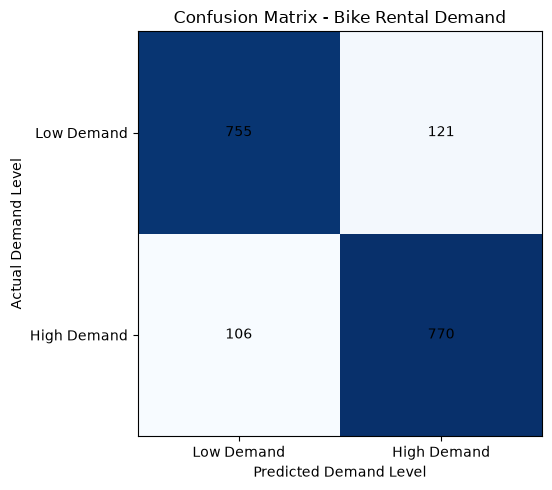

In [ ]:
# Predict demand levels using the test data
y_pred = model.predict(X_test_scaled)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("FEATURES USED:")
print(X_train.columns.tolist())

print("\nMODEL EVALUATION RESULTS:")
print("Accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nCONFUSION MATRIX:")
print(cm)

# Visualize the confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap = "Blues")
plt.title("Confusion Matrix - Bike Rental Demand")
plt.xlabel("Predicted Demand Level")
plt.ylabel("Actual Demand Level")
plt.xticks([0, 1], ["Low Demand", "High Demand"])
plt.yticks([0, 1], ["Low Demand", "High Demand"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

report = classification_report(y_test, y_pred)
print("\nMODEL CLASSIFICATION REPORT:")
print(report)
